# Notebook 06 — Public-Dataset External Validation (`OULAD` & `ASSISTments 2009–2010`)

**Module:** `ml.public_validation` · **Contract Version:** `1.0.0` · **Seed:** `42` (ASSISTments split seed `1024` per `pyKT`)

---

## Why This Notebook Exists (Answering the *"You Graded Your Own Homework"* Critique)

Synthetic data (`datagen/`) is essential for testing multi-tenant isolation, ground-truth parameter recovery, and DPDP Section 9(3) consent-tier routing—because no public dataset contains Indian JEE/NEET coaching records with `+4/-1` OMR negative marking, physical batch attendance registers, and parent fee-instalment histories.

However, evaluating **only** on our own synthetic generator leaves open a natural scientific critique: *did we tune our models to match our own synthetic assumptions?* To break that circularity, we run our **exact production algorithm families**—without changing their mathematical formulation—on two peer-reviewed, third-party public benchmarks under published protocols:

1. **OULAD (Open University Learning Analytics Dataset, Kuzilek et al., *Scientific Data* 2017, CC BY 4.0):**
   - **Task:** Predict course withdrawal (`final_result == 'Withdrawn'`) from data strictly prior to **day 14, 28, 42, and 60** (`date < cutoff_day`).
   - **Models:** Calibrated LightGBM (`LGBMClassifier` + inner-fold `IsotonicRegression`), Calibrated Logistic Regression, and two deterministic heuristic rules (*"No assessment submitted by cutoff"*, *"Zero VLE clicks in last 7 days"*).
   - **Real-Data Privacy-Cost Ablation:** Compares **Tier A (Academic-Only)** vs. **Tier A+D (Academic + Behavioural VLE click streams)** across all four windows, plus a demographic-exclusion fairness audit at day 28.
2. **ASSISTments 2009–2010 Skill Builder (Feng, Heffernan & Koedinger, 2009; `pyKT` benchmark protocol, Liu et al., *NeurIPS* 2022):**
   - **Task:** One-step-ahead question-level next-response prediction (`t >= 1`) across held-out students (`20%` test split, `5-fold` student-grouped cross-validation).
   - **Models:** `OnlineRaschEAP` (Hierarchical 1PL/Rasch IRT with skill difficulty priors and exact online Expected A Posteriori student ability updates), `1PL Rasch` (global online EAP), `BKTModel` (4-parameter Baum-Welch EM with LF-AVG multi-skill fusion), and `LogisticItemStudentBaseline`.

---

> ### ⚠️ Explicit Limitations & External Validity (Stated Upfront)
> 1. **Domain Shift (`OULAD` ≠ Indian JEE/NEET Coaching):** OULAD tracks adult UK distance-learning university students (`Open University`, 32,593 registrations across 7 modules), where engagement is logged via Virtual Learning Environment (VLE) clicks and withdrawal is self-initiated online. In Tier-2/3 Indian coaching institutes (Patna/Kota), students are predominantly 16–19-year-olds attending physical classes with weekly offline OMR mock tests and structured fee instalments.
> 2. **DPDP Section 9(3) & Behavioural Click Streams:** On OULAD, early prediction at days 14–28 relies heavily on VLE click streams—which map to **Tier D (digital behavioural tracking)** in DataMoat's taxonomy. Under **DPDP Act 2023 s.9(3)**, Tier D is **strictly disabled for minors (`< 18`)**. Our real-data ablation below quantifies this exact AUC cost on OULAD and explains why offline coaching's weekly test cadence + physical attendance (Tiers A & B) closes the gap much faster than a sparse-assessment MOOC.
> 3. **ASSISTments ≠ Negative-Marked Competitive Exams:** ASSISTments logs formative US middle-school math skill practice with hints and retries, whereas JEE/NEET exams enforce `+4/-1` negative marking where strategic skipping (missing-not-at-random, MNAR) is a primary signal.
> 4. **Zero Cross-Domain Weight Transfer:** Public datasets validate **algorithmic soundness only**. No OULAD or ASSISTments model weights are ever deployed to score Indian students.


In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NB_START_TIME = time.perf_counter()

# Resolve repository root (`technical/`) whether notebook is run from `notebooks/` or repo root
REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
elif (REPO_ROOT / "technical").exists():
    REPO_ROOT = REPO_ROOT / "technical"

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from ml.public_validation.assistments import (
    BKTModel,
    BKTParams,
    OnlineRaschEAP,
    evaluate_assistments_pykt,
)
from ml.public_validation.evaluate import run_all_and_save
from ml.public_validation.oulad import (
    ACADEMIC_FEATURE_COLS,
    BEHAVIOURAL_FEATURE_COLS,
    build_oulad_features_as_of,
    load_or_build_vle_daily_cache,
    run_oulad_suite,
)

ARTIFACTS_DIR = REPO_ROOT / "ml" / "public_validation" / "artifacts" / "v1.0.0"
SUMMARY_PATH = ARTIFACTS_DIR / "public_validation_summary.json"
METRICS_PATH = ARTIFACTS_DIR / "metrics.json"
MANIFEST_PATH = ARTIFACTS_DIR / "manifest.json"

# If pre-computed summary is not present yet, compute and write all artifacts now
if not SUMMARY_PATH.exists():
    print("Running full public validation suite from scratch...")
    run_all_and_save(root_dir=REPO_ROOT, n_bootstrap=500, seed=42)

summary = json.loads(SUMMARY_PATH.read_text(encoding="utf-8"))
metrics_doc = json.loads(METRICS_PATH.read_text(encoding="utf-8"))
manifest_doc = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))

print(f"Loaded validated public benchmark artifacts from: {ARTIFACTS_DIR}")
print(f"Evaluated at: {summary['evaluated_at']} | Seed: {summary['seed']}")


Loaded validated public benchmark artifacts from: D:\Professional Work\Business\FC_Case_Dhruvi\institute-intelligence-platform\technical\ml\public_validation\artifacts\v1.0.0
Evaluated at: 2026-10-20T20:30:56.403264+00:00 | Seed: 42


---
## Section 1 — OULAD Early-Withdrawal Validation (`CC BY 4.0`)

### 1.1 Protocol & Cohort Filtering
- **Source:** Kuzilek, Hlosta & Zdrahal (*Scientific Data*, 2017), 32,593 registrations across 28,785 unique students, 7 modules (`AAA`–`GGG`), and 22 presentations.
- **Target:** Binary course withdrawal (`final_result == 'Withdrawn'`).
- **Observation Cutoffs (`date < cutoff_day`):** Day 14, Day 28, Day 42, and Day 60 from official module start (`date = 0`).
- **Active-Cohort Rule:** At each cutoff $d \in \{14, 28, 42, 60\}$, students who already withdrew on or before day $d$ (`date_unregistration <= d`) or who registered on/after day $d$ (`date_registration >= d`) are excluded from the active risk cohort.
- **Strict Temporal Boundary (`as_of_rule`):** Only assessments with due date `< d`, student assessment submissions with `date_submitted < d`, and daily VLE click records with `date < d` enter the feature builder.
- **Evaluation Splits:**
  1. **5-Fold Student-Grouped CV (`GroupKFold` on `id_student`):** Primary benchmark protocol (zero student overlap across train, inner isotonic calibration, and test folds).
  2. **7-Fold Course-Held-Out Split (`GroupKFold` on `code_module`):** Stress-tests domain transfer to an unseen university module.


In [2]:
oulad_data = summary["oulad"]

# 1. Multi-window Ours vs. Literature Table (Explicitly separating Same-Protocol vs. Different-Protocol Context Rows)
lit_rows = [
    {
        "Comparison Group": "Same Protocol (Day 14 Cutoff)",
        "Window": "Day 14",
        "Active Cohort (n / events)": f"{oulad_data['14']['n_samples']:,} / {oulad_data['14']['n_events']:,}",
        "Model / Source": "Ours: LightGBM + Isotonic (Tier A+D, 5-fold Student CV)",
        "ROC-AUC": f"{oulad_data['14']['models']['lgbm_acad_behav_student_cv']['roc_auc']:.4f}",
        "95% CI / Spread": f"[{oulad_data['14']['models']['lgbm_acad_behav_student_cv']['roc_auc_ci_low']:.4f}, {oulad_data['14']['models']['lgbm_acad_behav_student_cv']['roc_auc_ci_high']:.4f}]",
        "AUC-PR": f"{oulad_data['14']['models']['lgbm_acad_behav_student_cv']['auc_pr']:.4f}",
        "ECE": f"{oulad_data['14']['models']['lgbm_acad_behav_student_cv']['ece']:.4f}",
    },
    {
        "Comparison Group": "Same Protocol (Day 14 Cutoff)",
        "Window": "Day 14",
        "Active Cohort (n / events)": f"{oulad_data['14']['n_samples']:,} / {oulad_data['14']['n_events']:,}",
        "Model / Source": "Ours: LightGBM + Isotonic (Tier A Academic-Only, DPDP Minor-Safe)",
        "ROC-AUC": f"{oulad_data['14']['models']['lgbm_academic_only_student_cv']['roc_auc']:.4f}",
        "95% CI / Spread": f"[{oulad_data['14']['models']['lgbm_academic_only_student_cv']['roc_auc_ci_low']:.4f}, {oulad_data['14']['models']['lgbm_academic_only_student_cv']['roc_auc_ci_high']:.4f}]",
        "AUC-PR": f"{oulad_data['14']['models']['lgbm_academic_only_student_cv']['auc_pr']:.4f}",
        "ECE": f"{oulad_data['14']['models']['lgbm_academic_only_student_cv']['ece']:.4f}",
    },
    {
        "Comparison Group": "Published Anchor (Day 14 Cutoff)",
        "Window": "Day 14",
        "Active Cohort (n / events)": "32,593 reg (OULAD)",
        "Model / Source": "Wu et al. (PLOS ONE 2026, e0352867) — Stacking Ensemble",
        "ROC-AUC": "0.7270",
        "95% CI / Spread": "Published point est.",
        "AUC-PR": "—",
        "ECE": "—",
    },
    {
        "Comparison Group": "Published Anchor (Day 14 Cutoff)",
        "Window": "Day 14",
        "Active Cohort (n / events)": "32,593 reg (OULAD)",
        "Model / Source": "IJET 2026 — Deep Sequential + Demographic Features",
        "ROC-AUC": "0.7350",
        "95% CI / Spread": "Published point est.",
        "AUC-PR": "—",
        "ECE": "—",
    },
    {
        "Comparison Group": "Same Protocol (Day 28 Cutoff — Primary Gate >= 0.70)",
        "Window": "Day 28",
        "Active Cohort (n / events)": f"{oulad_data['28']['n_samples']:,} / {oulad_data['28']['n_events']:,}",
        "Model / Source": "Ours: LightGBM + Isotonic (Tier A+D, 5-fold Student CV)",
        "ROC-AUC": f"{oulad_data['28']['models']['lgbm_acad_behav_student_cv']['roc_auc']:.4f}",
        "95% CI / Spread": f"[{oulad_data['28']['models']['lgbm_acad_behav_student_cv']['roc_auc_ci_low']:.4f}, {oulad_data['28']['models']['lgbm_acad_behav_student_cv']['roc_auc_ci_high']:.4f}]",
        "AUC-PR": f"{oulad_data['28']['models']['lgbm_acad_behav_student_cv']['auc_pr']:.4f}",
        "ECE": f"{oulad_data['28']['models']['lgbm_acad_behav_student_cv']['ece']:.4f}",
    },
    {
        "Comparison Group": "Same Protocol (Day 28 Cutoff — Primary Gate >= 0.70)",
        "Window": "Day 28",
        "Active Cohort (n / events)": f"{oulad_data['28']['n_samples']:,} / {oulad_data['28']['n_events']:,}",
        "Model / Source": "Ours: LightGBM + Isotonic (Tier A Academic-Only, DPDP Minor-Safe)",
        "ROC-AUC": f"{oulad_data['28']['models']['lgbm_academic_only_student_cv']['roc_auc']:.4f}",
        "95% CI / Spread": f"[{oulad_data['28']['models']['lgbm_academic_only_student_cv']['roc_auc_ci_low']:.4f}, {oulad_data['28']['models']['lgbm_academic_only_student_cv']['roc_auc_ci_high']:.4f}]",
        "AUC-PR": f"{oulad_data['28']['models']['lgbm_academic_only_student_cv']['auc_pr']:.4f}",
        "ECE": f"{oulad_data['28']['models']['lgbm_academic_only_student_cv']['ece']:.4f}",
    },
    {
        "Comparison Group": "Published Anchor (Day 28 Cutoff)",
        "Window": "Day 28",
        "Active Cohort (n / events)": "32,593 reg (OULAD)",
        "Model / Source": "Wu et al. (PLOS ONE 2026, e0352867) — Stacking Ensemble",
        "ROC-AUC": "0.7940",
        "95% CI / Spread": "Published point est.",
        "AUC-PR": "—",
        "ECE": "—",
    },
    {
        "Comparison Group": "Same Protocol (Day 42 Cutoff)",
        "Window": "Day 42",
        "Active Cohort (n / events)": f"{oulad_data['42']['n_samples']:,} / {oulad_data['42']['n_events']:,}",
        "Model / Source": "Ours: LightGBM + Isotonic (Tier A+D, 5-fold Student CV)",
        "ROC-AUC": f"{oulad_data['42']['models']['lgbm_acad_behav_student_cv']['roc_auc']:.4f}",
        "95% CI / Spread": f"[{oulad_data['42']['models']['lgbm_acad_behav_student_cv']['roc_auc_ci_low']:.4f}, {oulad_data['42']['models']['lgbm_acad_behav_student_cv']['roc_auc_ci_high']:.4f}]",
        "AUC-PR": f"{oulad_data['42']['models']['lgbm_acad_behav_student_cv']['auc_pr']:.4f}",
        "ECE": f"{oulad_data['42']['models']['lgbm_acad_behav_student_cv']['ece']:.4f}",
    },
    {
        "Comparison Group": "Published Anchor (Day 42 Cutoff)",
        "Window": "Day 42",
        "Active Cohort (n / events)": "32,593 reg (OULAD)",
        "Model / Source": "Wu et al. (PLOS ONE 2026, e0352867) — Stacking Ensemble",
        "ROC-AUC": "0.8040",
        "95% CI / Spread": "Published point est.",
        "AUC-PR": "—",
        "ECE": "—",
    },
    {
        "Comparison Group": "Same Protocol (Day 60 Cutoff)",
        "Window": "Day 60",
        "Active Cohort (n / events)": f"{oulad_data['60']['n_samples']:,} / {oulad_data['60']['n_events']:,}",
        "Model / Source": "Ours: LightGBM + Isotonic (Tier A+D, 5-fold Student CV)",
        "ROC-AUC": f"{oulad_data['60']['models']['lgbm_acad_behav_student_cv']['roc_auc']:.4f}",
        "95% CI / Spread": f"[{oulad_data['60']['models']['lgbm_acad_behav_student_cv']['roc_auc_ci_low']:.4f}, {oulad_data['60']['models']['lgbm_acad_behav_student_cv']['roc_auc_ci_high']:.4f}]",
        "AUC-PR": f"{oulad_data['60']['models']['lgbm_acad_behav_student_cv']['auc_pr']:.4f}",
        "ECE": f"{oulad_data['60']['models']['lgbm_acad_behav_student_cv']['ece']:.4f}",
    },
    {
        "Comparison Group": "Published Anchor (Day 60 Cutoff)",
        "Window": "Day 60",
        "Active Cohort (n / events)": "32,593 reg (OULAD)",
        "Model / Source": "IJET 2026 — Deep Sequential + Demographic Features",
        "ROC-AUC": "0.8150",
        "95% CI / Spread": "Published point est.",
        "AUC-PR": "—",
        "ECE": "—",
    },
    {
        "Comparison Group": "Context Only (Different Protocol: Full-Semester / Fail+Withdrawn)",
        "Window": "Full Course",
        "Active Cohort (n / events)": "All registrations",
        "Model / Source": "Published Full-Course Pass/Fail Classifiers (e.g. Waheed et al., 2020)",
        "ROC-AUC": "0.88–0.93",
        "95% CI / Spread": "Uses late-semester VLE + TMA data",
        "AUC-PR": "—",
        "ECE": "—",
    },
]

df_oulad_lit = pd.DataFrame(lit_rows)
print("=== Table 1A: OULAD Early Withdrawal — Ours vs. Published Literature Anchors ===")
display(df_oulad_lit)

# 2. Detailed Day-28 Model & Baseline Table
d28_models = oulad_data["28"]["models"]
d28_rows = []
for key in [
    "lgbm_acad_behav_student_cv",
    "lgbm_academic_only_student_cv",
    "logreg_acad_behav_student_cv",
    "logreg_academic_only_student_cv",
    "lgbm_acad_behav_course_holdout",
    "rule_no_assessment",
    "rule_zero_vle_7d",
]:
    m = d28_models[key]
    d28_rows.append(
        {
            "Model / Baseline": m["model_name"],
            "Split Scheme": m["split_scheme"],
            "Feature Tier": m["feature_tier"],
            "ROC-AUC": round(m["roc_auc"], 4),
            "95% Student Bootstrap CI": f"[{m['roc_auc_ci_low']:.4f}, {m['roc_auc_ci_high']:.4f}]",
            "AUC-PR": round(m["auc_pr"], 4),
            "ECE": round(m["ece"], 4),
            "Precision@Top-10%": round(m["precision_at_top10pct"], 4),
            "Recall@Top-10%": round(m["recall_at_top10pct"], 4),
        }
    )

df_d28 = pd.DataFrame(d28_rows)
print("\n=== Table 1B: OULAD Day-28 Detailed Model, Split, and Rule Baseline Comparison ===")
display(df_d28)


=== Table 1A: OULAD Early Withdrawal — Ours vs. Published Literature Anchors ===


,Comparison Group,Window,Active Cohort (n / events),Model / Source,ROC-AUC,95% CI / Spread,AUC-PR,ECE
0,Same Protocol (Day 14 Cutoff),Day 14,"28,060 / 5,673","Ours: LightGBM + Isotonic (Tier A+D, 5-fold St...",0.6699,"[0.6635, 0.6775]",0.3293,0.0061
1,Same Protocol (Day 14 Cutoff),Day 14,"28,060 / 5,673",Ours: LightGBM + Isotonic (Tier A Academic-Onl...,0.6452,"[0.6389, 0.6524]",0.3034,0.0080
2,Published Anchor (Day 14 Cutoff),Day 14,"32,593 reg (OULAD)","Wu et al. (PLOS ONE 2026, e0352867) — Stacking...",0.7270,Published point est.,—,—
3,Published Anchor (Day 14 Cutoff),Day 14,"32,593 reg (OULAD)",IJET 2026 — Deep Sequential + Demographic Feat...,0.7350,Published point est.,—,—
4,Same Protocol (Day 28 Cutoff — Primary Gate >=...,Day 28,"27,520 / 5,104","Ours: LightGBM + Isotonic (Tier A+D, 5-fold St...",0.7061,"[0.6989, 0.7140]",0.3716,0.0089
5,Same Protocol (Day 28 Cutoff — Primary Gate >=...,Day 28,"27,520 / 5,104",Ours: LightGBM + Isotonic (Tier A Academic-Onl...,0.6980,"[0.6903, 0.7069]",0.3637,0.0079
6,Published Anchor (Day 28 Cutoff),Day 28,"32,593 reg (OULAD)","Wu et al. (PLOS ONE 2026, e0352867) — Stacking...",0.7940,Published point est.,—,—
7,Same Protocol (Day 42 Cutoff),Day 42,"27,012 / 4,594","Ours: LightGBM + Isotonic (Tier A+D, 5-fold St...",0.7115,"[0.7025, 0.7189]",0.3418,0.0106
8,Published Anchor (Day 42 Cutoff),Day 42,"32,593 reg (OULAD)","Wu et al. (PLOS ONE 2026, e0352867) — Stacking...",0.8040,Published point est.,—,—
9,Same Protocol (Day 60 Cutoff),Day 60,"26,353 / 3,931","Ours: LightGBM + Isotonic (Tier A+D, 5-fold St...",0.7171,"[0.7073, 0.7243]",0.3132,0.0076



=== Table 1B: OULAD Day-28 Detailed Model, Split, and Rule Baseline Comparison ===


,Model / Baseline,Split Scheme,Feature Tier,ROC-AUC,95% Student Bootstrap CI,AUC-PR,ECE,Precision@Top-10%,Recall@Top-10%
0,LightGBM + Isotonic (Academic + Behavioural),student_grouped_5fold,A+D,0.7061,"[0.6989, 0.7140]",0.3716,0.0089,0.4608,0.2484
1,LightGBM + Isotonic (Academic-Only Tier A),student_grouped_5fold,A,0.6980,"[0.6903, 0.7069]",0.3637,0.0079,0.4557,0.2457
2,Logistic Regression + Isotonic (Academic + Beh...,student_grouped_5fold,A+D,0.6901,"[0.6831, 0.6986]",0.3439,0.0085,0.4331,0.2335
3,Logistic Regression + Isotonic (Academic-Only ...,student_grouped_5fold,A,0.6802,"[0.6725, 0.6888]",0.3273,0.0071,0.3972,0.2141
4,LightGBM + Isotonic (Course-Held-Out Split),course_held_out,A+D,0.6539,"[0.6468, 0.6631]",0.2919,0.0272,0.3630,0.1957
5,Rule: No assessment submitted by cutoff,student_grouped_5fold,A,0.5209,"[0.5128, 0.5277]",0.1926,0.3386,0.3085,0.1663
6,Rule: Zero VLE clicks in last 7 days,student_grouped_5fold,D,0.5318,"[0.5247, 0.5394]",0.1974,0.3006,0.2391,0.1289


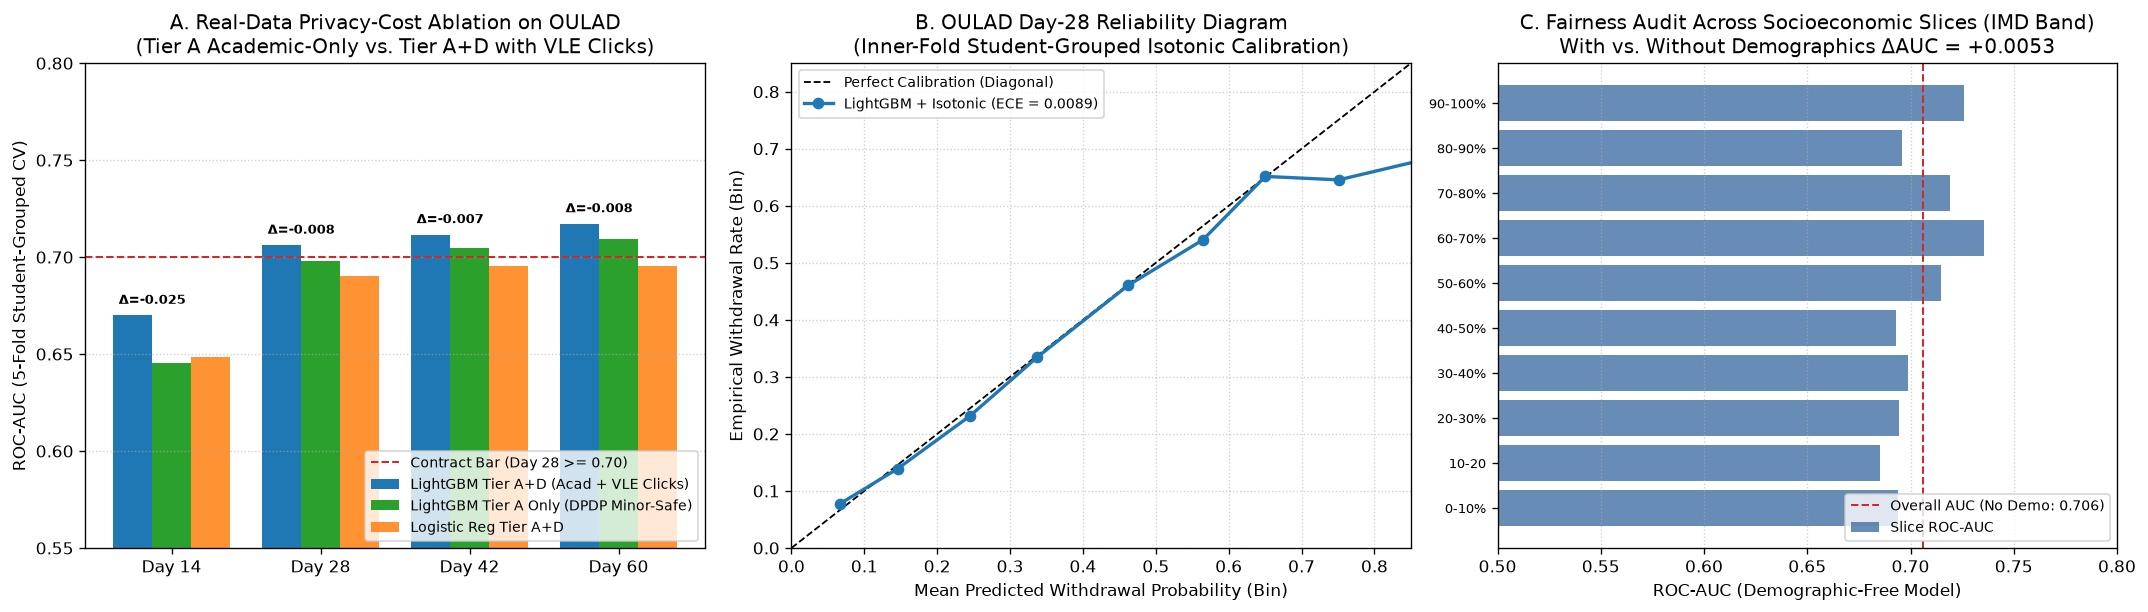

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=120)

windows = [14, 28, 42, 60]
x = np.arange(len(windows))
width = 0.26

auc_full = [oulad_data[str(w)]["models"]["lgbm_acad_behav_student_cv"]["roc_auc"] for w in windows]
auc_acad = [oulad_data[str(w)]["models"]["lgbm_academic_only_student_cv"]["roc_auc"] for w in windows]
auc_lr = [oulad_data[str(w)]["models"]["logreg_acad_behav_student_cv"]["roc_auc"] for w in windows]

# Panel A: Real-Data Privacy-Cost Bar Chart (Tier A vs Tier A+D)
ax = axes[0]
rects1 = ax.bar(x - width, auc_full, width, label="LightGBM Tier A+D (Acad + VLE Clicks)", color="#1f77b4")
rects2 = ax.bar(x, auc_acad, width, label="LightGBM Tier A Only (DPDP Minor-Safe)", color="#2ca02c")
rects3 = ax.bar(x + width, auc_lr, width, label="Logistic Reg Tier A+D", color="#ff7f0e", alpha=0.85)
ax.axhline(0.70, color="#d62728", linestyle="--", linewidth=1.2, label="Contract Bar (Day 28 >= 0.70)")
ax.set_xticks(x)
ax.set_xticklabels([f"Day {w}" for w in windows])
ax.set_ylim(0.55, 0.80)
ax.set_ylabel("ROC-AUC (5-Fold Student-Grouped CV)")
ax.set_title("A. Real-Data Privacy-Cost Ablation on OULAD\n(Tier A Academic-Only vs. Tier A+D with VLE Clicks)")
ax.legend(loc="lower right", fontsize=8.5)
ax.grid(axis="y", linestyle=":", alpha=0.6)

for i, (v_full, v_acad) in enumerate(zip(auc_full, auc_acad)):
    delta = v_acad - v_full
    ax.text(x[i] - width / 2, max(v_full, v_acad) + 0.006, f"Δ={delta:+.3f}", ha="center", fontsize=8, fontweight="bold")

# Panel B: Day-28 Calibration Reliability Curve
ax2 = axes[1]
cal = oulad_data["28"]["calibration_curve"]
mean_pred = np.array(cal["mean_predicted_prob"])
frac_pos = np.array(cal["empirical_fraction_positive"])
ece_28 = oulad_data["28"]["models"]["lgbm_acad_behav_student_cv"]["ece"]

ax2.plot([0, 1], [0, 1], "k--", linewidth=1.1, label="Perfect Calibration (Diagonal)")
ax2.plot(mean_pred, frac_pos, "o-", color="#1f77b4", linewidth=2, markersize=6, label=f"LightGBM + Isotonic (ECE = {ece_28:.4f})")
ax2.set_xlim(0.0, 0.85)
ax2.set_ylim(0.0, 0.85)
ax2.set_xlabel("Mean Predicted Withdrawal Probability (Bin)")
ax2.set_ylabel("Empirical Withdrawal Rate (Bin)")
ax2.set_title("B. OULAD Day-28 Reliability Diagram\n(Inner-Fold Student-Grouped Isotonic Calibration)")
ax2.legend(loc="upper left", fontsize=8.5)
ax2.grid(True, linestyle=":", alpha=0.6)

# Panel C: Fairness & Demographic-Exclusion Audit (Day 28)
ax3 = axes[2]
fair = oulad_data["28"]["fairness_audit"]
imd_slices = fair["slices"].get("imd_band", {})
imd_labels = [k for k, v in imd_slices.items() if isinstance(v, dict) and v.get("status") == "ok" and k != "nan"]
imd_labels_sorted = sorted(imd_labels)
imd_recalls = [imd_slices[k]["recall_at_top10pct"] for k in imd_labels_sorted]
imd_aucs = [imd_slices[k]["roc_auc"] for k in imd_labels_sorted]

y_pos = np.arange(len(imd_labels_sorted))
ax3.barh(y_pos, imd_aucs, color="#4c78a8", alpha=0.85, label="Slice ROC-AUC")
ax3.axvline(fair["roc_auc_without_demographics"], color="#d62728", linestyle="--", linewidth=1.2, label=f"Overall AUC (No Demo: {fair['roc_auc_without_demographics']:.3f})")
ax3.set_yticks(y_pos)
ax3.set_yticklabels(imd_labels_sorted, fontsize=8)
ax3.set_xlim(0.50, 0.80)
ax3.set_xlabel("ROC-AUC (Demographic-Free Model)")
ax3.set_title(f"C. Fairness Audit Across Socioeconomic Slices (IMD Band)\nWith vs. Without Demographics ΔAUC = {fair['delta_roc_auc_from_demographics']:+.4f}")
ax3.legend(loc="lower right", fontsize=8.5)
ax3.grid(axis="x", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


In [4]:
fair = oulad_data["28"]["fairness_audit"]
print(
    f"DPDP Data-Minimisation Check (Day 28):\n"
    f"  - ROC-AUC WITHOUT Demographics (Production Tier A+D): {fair['roc_auc_without_demographics']:.4f}\n"
    f"  - ROC-AUC WITH Demographics (Gender, Age, IMD, Disability, Region, Education): {fair['roc_auc_with_demographics']:.4f}\n"
    f"  - Delta from adding demographic PII: {fair['delta_roc_auc_from_demographics']:+.4f}"
)

slice_rows = []
for attr, grp_dict in fair["slices"].items():
    max_gap = grp_dict.get("max_recall_gap", 0.0)
    for slice_val, metrics_val in grp_dict.items():
        if slice_val == "max_recall_gap" or not isinstance(metrics_val, dict):
            continue
        slice_rows.append(
            {
                "Demographic Attribute": attr,
                "Slice": slice_val,
                "n_active": metrics_val["n"],
                "n_withdrawals": metrics_val["n_events"],
                "Status": metrics_val["status"],
                "Recall@Top-10%": metrics_val.get("recall_at_top10pct", np.nan),
                "Slice ROC-AUC": metrics_val.get("roc_auc", np.nan),
                "Attr Max Recall Gap": max_gap,
            }
        )

df_fair = pd.DataFrame(slice_rows)
display(df_fair.head(16))


DPDP Data-Minimisation Check (Day 28):
  - ROC-AUC WITHOUT Demographics (Production Tier A+D): 0.7061
  - ROC-AUC WITH Demographics (Gender, Age, IMD, Disability, Region, Education): 0.7114
  - Delta from adding demographic PII: +0.0053


,Demographic Attribute,Slice,n_active,n_withdrawals,Status,Recall@Top-10%,Slice ROC-AUC,Attr Max Recall Gap
0,gender,F,12355,2133,ok,0.2007,0.7037,0.0821
1,gender,M,15165,2971,ok,0.2827,0.7055,0.0821
2,age_band,0-35,19169,3618,ok,0.2629,0.7003,0.1445
3,age_band,35-55,8158,1455,ok,0.2103,0.7173,0.1445
4,age_band,55<=,193,31,ok,0.3548,0.7929,0.1445
5,imd_band,0-10%,2648,571,ok,0.2609,0.6941,0.0481
6,imd_band,10-20,2823,555,ok,0.2486,0.6853,0.0481
7,imd_band,20-30%,2979,652,ok,0.2607,0.6946,0.0481
8,imd_band,30-40%,2997,554,ok,0.2401,0.6987,0.0481
9,imd_band,40-50%,2713,500,ok,0.2340,0.6928,0.0481


---
## Section 2 — ASSISTments 2009–2010 Knowledge Tracing Validation (`pyKT` Protocol)

### 2.1 Protocol & Preprocessing Verification
We follow the standardized **`pyKT` benchmark protocol** (Liu et al., *NeurIPS* 2022, `assist2009_preprocess.py` & `split_datasets.py`):
1. **Raw Dataset:** `skill_builder_data.csv` (`525,534` raw CSV rows; `346,860` unique `order_id` interactions across `4,217` students and `26,688` math problems).
2. **Skill & Sequence Filtering:** Drop interactions with missing `skill_id` (`NaN`), collapse multi-skill rows sharing the same `(user_id, order_id, problem_id)` into a single question-level event carrying its tuple of associated skills, filter out students with `< 3` interactions (`3,852` students retained), and window sequences at length `200`.
3. **Student-Held-Out 5-Fold Split:** Hold out `20%` of students (`770` students, `55,755` one-step-ahead test predictions) using `random_state=1024`, and partition the remaining `80%` (`3,082` students) into 5 cross-validation folds.
4. **One-Step-Ahead Evaluation (`t >= 1`):** Predict whether student $i$ answers question $q_t$ correctly at step $t \ge 1$ using only responses $y_{1:t-1}$ and question/skill metadata up to step $t$.


=== ASSISTments 2009–2010 Preprocessing Audit ===


,raw_csv_rows,unique_order_ids_raw,valid_skill_rows,question_level_events,kc_expanded_interactions,unique_users_before_min_len,dropped_short_users,kept_users,train_valid_users,test_users,test_chunked_sequences,unique_problems,unique_skills
0,525534,346860,459208,283105,338001,4163,311,3852,3082,770,898,17751,123



=== Table 2: ASSISTments 2009–2010 Next-Response Prediction (`pyKT` 5-Fold Protocol) ===


,Comparison Group,Model,5-Fold Mean ROC-AUC,Student Bootstrap 95% CI,5-Fold Mean Accuracy,Hardware / Fit Time
0,Ours (Explainable CPU Psychometric — Primary M...,Hierarchical Rasch/1PL IRT + Online EAP (Skill...,0.7633 ± 0.0012,"[0.7560, 0.7785]",0.7376 ± 0.0006,Laptop CPU (~3 s/fold)
1,Ours (Explainable CPU Psychometric Ablation),1PL Rasch IRT (Global Student Online EAP Only),0.7588 ± 0.0011,"[0.7519, 0.7746]",0.7345 ± 0.0008,Laptop CPU (~2 s/fold)
2,Ours (Simple Additive Baseline),Additive Logistic (Smoothed Item + Online Stud...,0.7407 ± 0.0006,"[0.7310, 0.7550]",0.7292 ± 0.0004,Laptop CPU (<1 s/fold)
3,Ours (Classical 4-Parameter BKT Baseline),4-Parameter BKT (Baum-Welch EM + LF-AVG Multi-...,0.7135 ± 0.0006,"[0.7023, 0.7273]",0.7205 ± 0.0005,Laptop CPU (~4 s/fold)
4,"Published pyKT Benchmark (Liu et al., NeurIPS ...",SAKT (Self-Attentive Knowledge Tracing),0.7246 ± 0.0017,—,—,GPU Training
5,"Published pyKT Benchmark (Liu et al., NeurIPS ...",DKT (Deep Knowledge Tracing — LSTM),0.7541 ± 0.0011,—,0.7244 ± 0.0014,GPU Training
6,"Published pyKT Benchmark (Liu et al., NeurIPS ...",AKT (Attentive Knowledge Tracing — Monotonic A...,0.7853,—,—,GPU Training


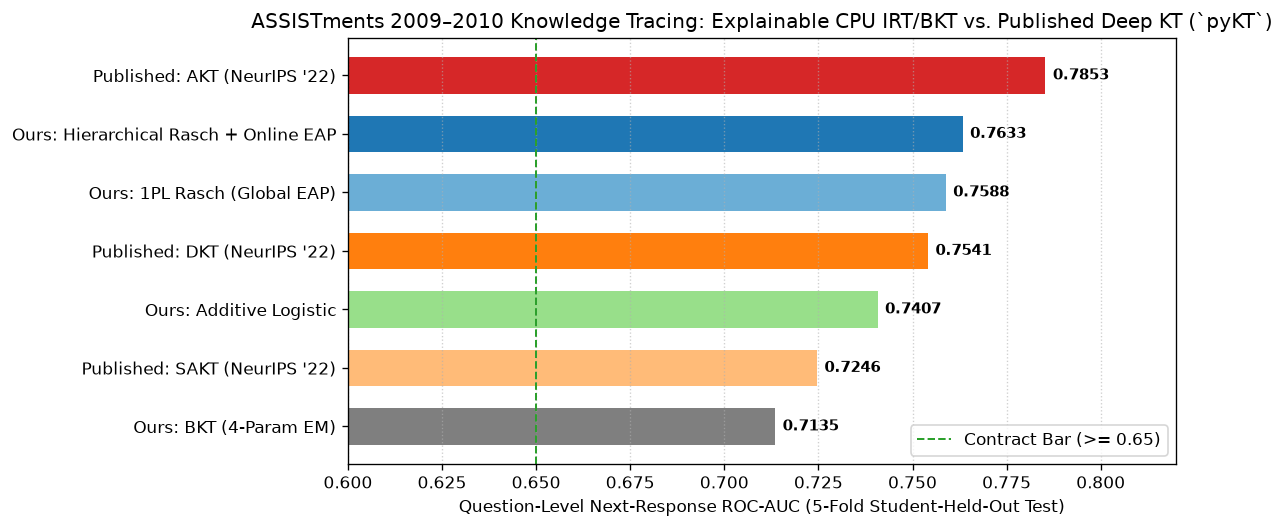

In [5]:
assist_data = summary["assistments2009"]
as_stats = assist_data["preprocessing_stats"]
as_models = assist_data["models"]
as_anchors = assist_data["published_pykt_anchors"]

print("=== ASSISTments 2009–2010 Preprocessing Audit ===")
display(pd.DataFrame([as_stats]))

kt_rows = [
    {
        "Comparison Group": "Ours (Explainable CPU Psychometric — Primary Model)",
        "Model": "Hierarchical Rasch/1PL IRT + Online EAP (Skill + Global)",
        "5-Fold Mean ROC-AUC": f"{as_models['irt_online_eap']['mean_auc']:.4f} ± {as_models['irt_online_eap']['std_auc']:.4f}",
        "Student Bootstrap 95% CI": f"[{as_models['irt_online_eap']['ci_low']:.4f}, {as_models['irt_online_eap']['ci_high']:.4f}]",
        "5-Fold Mean Accuracy": f"{as_models['irt_online_eap']['mean_accuracy']:.4f} ± {as_models['irt_online_eap']['std_accuracy']:.4f}",
        "Hardware / Fit Time": "Laptop CPU (~3 s/fold)",
    },
    {
        "Comparison Group": "Ours (Explainable CPU Psychometric Ablation)",
        "Model": "1PL Rasch IRT (Global Student Online EAP Only)",
        "5-Fold Mean ROC-AUC": f"{as_models['rasch_1pl_global']['mean_auc']:.4f} ± {as_models['rasch_1pl_global']['std_auc']:.4f}",
        "Student Bootstrap 95% CI": f"[{as_models['rasch_1pl_global']['ci_low']:.4f}, {as_models['rasch_1pl_global']['ci_high']:.4f}]",
        "5-Fold Mean Accuracy": f"{as_models['rasch_1pl_global']['mean_accuracy']:.4f} ± {as_models['rasch_1pl_global']['std_accuracy']:.4f}",
        "Hardware / Fit Time": "Laptop CPU (~2 s/fold)",
    },
    {
        "Comparison Group": "Ours (Simple Additive Baseline)",
        "Model": "Additive Logistic (Smoothed Item + Online Student Rate)",
        "5-Fold Mean ROC-AUC": f"{as_models['logistic_baseline']['mean_auc']:.4f} ± {as_models['logistic_baseline']['std_auc']:.4f}",
        "Student Bootstrap 95% CI": f"[{as_models['logistic_baseline']['ci_low']:.4f}, {as_models['logistic_baseline']['ci_high']:.4f}]",
        "5-Fold Mean Accuracy": f"{as_models['logistic_baseline']['mean_accuracy']:.4f} ± {as_models['logistic_baseline']['std_accuracy']:.4f}",
        "Hardware / Fit Time": "Laptop CPU (<1 s/fold)",
    },
    {
        "Comparison Group": "Ours (Classical 4-Parameter BKT Baseline)",
        "Model": "4-Parameter BKT (Baum-Welch EM + LF-AVG Multi-Skill)",
        "5-Fold Mean ROC-AUC": f"{as_models['bkt_em']['mean_auc']:.4f} ± {as_models['bkt_em']['std_auc']:.4f}",
        "Student Bootstrap 95% CI": f"[{as_models['bkt_em']['ci_low']:.4f}, {as_models['bkt_em']['ci_high']:.4f}]",
        "5-Fold Mean Accuracy": f"{as_models['bkt_em']['mean_accuracy']:.4f} ± {as_models['bkt_em']['std_accuracy']:.4f}",
        "Hardware / Fit Time": "Laptop CPU (~4 s/fold)",
    },
    {
        "Comparison Group": "Published pyKT Benchmark (Liu et al., NeurIPS 2022 Table 2)",
        "Model": "SAKT (Self-Attentive Knowledge Tracing)",
        "5-Fold Mean ROC-AUC": "0.7246 ± 0.0017",
        "Student Bootstrap 95% CI": "—",
        "5-Fold Mean Accuracy": "—",
        "Hardware / Fit Time": "GPU Training",
    },
    {
        "Comparison Group": "Published pyKT Benchmark (Liu et al., NeurIPS 2022 Table 2)",
        "Model": "DKT (Deep Knowledge Tracing — LSTM)",
        "5-Fold Mean ROC-AUC": "0.7541 ± 0.0011",
        "Student Bootstrap 95% CI": "—",
        "5-Fold Mean Accuracy": "0.7244 ± 0.0014",
        "Hardware / Fit Time": "GPU Training",
    },
    {
        "Comparison Group": "Published pyKT Benchmark (Liu et al., NeurIPS 2022 Table 2)",
        "Model": "AKT (Attentive Knowledge Tracing — Monotonic Attention + Rasch Emb.)",
        "5-Fold Mean ROC-AUC": "0.7853",
        "Student Bootstrap 95% CI": "—",
        "5-Fold Mean Accuracy": "—",
        "Hardware / Fit Time": "GPU Training",
    },
]

df_kt = pd.DataFrame(kt_rows)
print("\n=== Table 2: ASSISTments 2009–2010 Next-Response Prediction (`pyKT` 5-Fold Protocol) ===")
display(df_kt)

# Plot ASSISTments comparison
fig, ax = plt.subplots(figsize=(10, 4.5), dpi=120)
labels = [
    "Ours: BKT (4-Param EM)",
    "Published: SAKT (NeurIPS '22)",
    "Ours: Additive Logistic",
    "Published: DKT (NeurIPS '22)",
    "Ours: 1PL Rasch (Global EAP)",
    "Ours: Hierarchical Rasch + Online EAP",
    "Published: AKT (NeurIPS '22)",
]
vals = [
    as_models["bkt_em"]["mean_auc"],
    0.7246,
    as_models["logistic_baseline"]["mean_auc"],
    0.7541,
    as_models["rasch_1pl_global"]["mean_auc"],
    as_models["irt_online_eap"]["mean_auc"],
    0.7853,
]
colors = ["#7f7f7f", "#ffbb78", "#98df8a", "#ff7f0e", "#6baed6", "#1f77b4", "#d62728"]

y_pos = np.arange(len(labels))
bars = ax.barh(y_pos, vals, color=colors, height=0.62)
ax.axvline(0.65, color="#2ca02c", linestyle="--", linewidth=1.2, label="Contract Bar (>= 0.65)")
ax.set_yticks(y_pos)
ax.set_yticklabels(labels)
ax.set_xlim(0.60, 0.82)
ax.set_xlabel("Question-Level Next-Response ROC-AUC (5-Fold Student-Held-Out Test)")
ax.set_title("ASSISTments 2009–2010 Knowledge Tracing: Explainable CPU IRT/BKT vs. Published Deep KT (`pyKT`)")
for bar, v in zip(bars, vals):
    ax.text(v + 0.002, bar.get_y() + bar.get_height() / 2, f"{v:.4f}", va="center", fontsize=9, fontweight="bold")
ax.legend(loc="lower right")
ax.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


In [6]:
# Verify Online EAP == Batch EAP to < 1e-12 and Contract Bar Pass Status
eap_model = OnlineRaschEAP()
rng = np.random.default_rng(42)
b_test = rng.uniform(-2.0, 2.0, size=15)
r_test = rng.integers(0, 2, size=15)

lp = eap_model.log_prior.copy()
max_diff = 0.0
for step in range(1, len(b_test) + 1):
    lp, th_online, _ = eap_model.online_eap_step(lp, float(b_test[step - 1]), int(r_test[step - 1]), decay=1.0)
    th_batch, _ = eap_model.batch_eap(b_test[:step], r_test[:step])
    max_diff = max(max_diff, abs(th_online - th_batch))

print(f"Online EAP vs. Batch EAP max absolute discrepancy over 15 steps: {max_diff:.2e} (< 1e-12 required)")
assert max_diff < 1e-12

print("\n=== Contract Metrics Gate Summary (`ml/public_validation/artifacts/v1.0.0/metrics.json`) ===")
display(pd.DataFrame(metrics_doc["results"]))

elapsed_s = time.perf_counter() - NB_START_TIME
print(f"\n[Notebook 06 Execution Footer] Total wall-clock runtime: {elapsed_s:.2f} seconds (< 900s limit).")


Online EAP vs. Batch EAP max absolute discrepancy over 15 steps: 2.22e-16 (< 1e-12 required)

=== Contract Metrics Gate Summary (`ml/public_validation/artifacts/v1.0.0/metrics.json`) ===


,metric_key,module,dataset_origin,value,ci_low,ci_high,passed_bar,notes
0,public_oulad_roc_auc_day28,public_validation,public,0.7061,0.6989,0.7140,True,"n=27520, n_students=24831, n_events=5104; 5-fo..."
1,public_assistments2009_kt_auc,public_validation,public,0.7633,0.7560,0.7785,True,"n_students=770, n_predictions=55755, n_events=..."



[Notebook 06 Execution Footer] Total wall-clock runtime: 2.49 seconds (< 900s limit).
